In [90]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression,SGDClassifier
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split,cross_validate,StratifiedKFold,GridSearchCV
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [91]:
# 피쳐에 대한 정보입니다.
# 이 정보를 가지고 피쳐에대한 연봉예측 linearRegression ai를 구현하시오
# picher_stats_2017.csv

In [100]:
# 데이터 가져오기 

df = pd.read_csv('data/picher_stats_2017.csv',index_col='선수명')
df.head(2)

# data = df[df.columns[2]].values

label = df['연봉(2018)']
data = df.drop(columns=['연봉(2018)','팀명']).values

team = df['팀명'].to_numpy().reshape(-1,1)
num_data = df.drop(columns=['연봉(2018)','팀명']).values
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(team)
data = np.concatenate((num_data,result),axis=1)


train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

df

,팀명,승,패,세,홀드,블론,경기,선발,이닝,삼진/9,...,홈런/9,BABIP,LOB%,ERA,RA9-WAR,FIP,kFIP,WAR,연봉(2018),연봉(2017)
선수명,,,,,,,,,,,,,,,,,,,,,
켈리,SK,16,7,0,0,0,30,30,190.0,8.95,...,0.76,0.342,73.7,3.60,6.91,3.69,3.44,6.62,140000,85000
소사,LG,11,11,1,0,0,30,29,185.1,7.43,...,0.53,0.319,67.1,3.88,6.80,3.52,3.41,6.08,120000,50000
양현종,KIA,20,6,0,0,0,31,31,193.1,7.36,...,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,230000,150000
차우찬,LG,10,7,0,0,0,28,28,175.2,8.04,...,1.02,0.298,75.0,3.43,6.11,4.20,4.03,4.63,100000,100000
레일리,롯데,13,7,0,0,0,30,30,187.1,7.49,...,0.91,0.323,74.1,3.80,6.13,4.36,4.31,4.38,111000,85000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
장민재,한화,2,5,0,0,2,33,5,62.2,4.31,...,1.58,0.355,56.9,7.76,-1.21,6.21,6.48,-0.47,7100,8100
정용운,KIA,3,2,0,0,0,25,11,59.1,4.85,...,1.06,0.263,65.4,5.92,0.39,6.41,6.77,-0.49,7500,3100
노경은,롯데,0,2,0,0,0,9,2,14.2,4.91,...,2.45,0.382,52.8,11.66,-0.83,8.03,8.29,-0.61,10000,16000


In [101]:
# # 다중화
# poly = PolynomialFeatures(degree=3,include_bias=False)
# poly.fit(train_data)
# train_poly = poly.transform(train_data)
# test_poly = poly.transform(test_data)

In [102]:
# # # 다중화+정규화
# ss= StandardScaler()
# ss.fit(train_poly)
# train_scaled = ss.transform(train_poly)
# test_scaled = ss.transform(test_poly)

In [103]:
# 정규화
ss= StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [104]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_scaled,train_label)

# 데이터 예측
predict = lr.predict(test_scaled)

# 정확도 

print('train_정확도',lr.score(train_scaled,train_label))
print('test_정확도',lr.score(test_scaled,test_label))

train_정확도 0.9344519586230713
test_정확도 0.7330121587681977


In [105]:
rf = RandomForestRegressor(n_jobs=-1,random_state=42)
rf.fit(train_scaled,train_label)
print('train_정확도',rf.score(train_scaled,train_label))
print('test_정확도',rf.score(test_scaled,test_label))



# scores = cross_validate(rf,train_scaled,train_label,return_train_score=True,n_jobs=-1)

# print(scores['train_score'])
# print(scores['test_score'])
# print(np.mean(scores['train_score']))
# print(np.mean(scores['test_score']))
# print(rf.feature_importances_)

train_정확도 0.9674741099973113
test_정확도 0.8895795113106733


In [106]:
params = {
    'alpha':[0.001,0.01,0.1,1,10,100]
}
gs =GridSearchCV(Ridge(),params)
gs.fit(train_scaled,train_label)

ridge = gs.best_estimator_
print(gs.best_params_)
print(gs.best_score_)
print('train_정확도',ridge.score(train_scaled,train_label))
print('test_정확도',ridge.score(test_scaled,test_label))

{'alpha': 10}
0.8489392836255198
train_정확도 0.9249253914492839
test_정확도 0.8094794963343103


In [99]:
# # in_data = '16,7,0,0,0,30,30,190.0,8.95,2.13,0.76,0.342,73.7,3.6,6.91,3.69,3.44,6.62,85000'
# # in_data = '11,11,1,0,0,30,29,185.1,7.43,1.85,0.53,0.319,67.1,3.88,6.8,3.52,3.41,6.08,50000'
# in_data = '20,6,0,0,0,31,31,193.1,7.36,2.09,0.79,0.332,72.1,3.44,6.54,3.94,3.82,5.64,150000'

# in_data = list(map(float,in_data.split(',')))
# in_data = ss.transform([in_data])
# print(rf.predict(in_data))
# print(gs.predict(in_data))

In [107]:
# pip install statsmodels
# 회귀분석 통계결과표 : P>|t| 통계량의 절대값보다 크거나 같은 값이 나올 확률
import statsmodels.api as sm

train_scaled = sm.add_constant(train_scaled)
model = sm.OLS(train_label,train_scaled).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               연봉(2018)   R-squared:                       0.934
Model:                            OLS   Adj. R-squared:                  0.914
Method:                 Least Squares   F-statistic:                     45.41
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           5.19e-40
Time:                        15:18:27   Log-Likelihood:                -1195.6
No. Observations:                 114   AIC:                             2447.
Df Residuals:                      86   BIC:                             2524.
Df Model:                          27                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.986e+04    936.224     21.208      0.000     1.8e+04    2.17e+04
x1          4404.6583   2986.826      1.475      0.144   -1532.955    1.03e+04
x2          -755.9644   2393.792     -0.316      0.753   -5514.666    4002.737
x3          -379.8537   1609.849     -0.236      0.814   -3580.128    2820.420
x4          -914.8103   1727.638     -0.530      0.598   -4349.241    2519.621
x5           998.2166   1605.834      0.622      0.536   -2194.076    4190.510
x6         -4599.2812   3912.123     -1.176      0.243   -1.24e+04    3177.762
x7         -1.247e+04   6850.819     -1.821      0.072   -2.61e+04    1145.594
x8          1.052e+04   8941.923      1.177      0.243   -7254.037    2.83e+04
x9          2339.4510   6747.109      0.347      0.730   -1.11e+04    1.58e+04
x10         5218.1272   6422.864      0.812      0.419   -7550.103     1.8e+04
x11         9619.9882   1.43e+04      0.671      0.504   -1.89e+04    3.81e+04
x12        -1734.3012   1413.108     -1.227      0.223   -4543.468    1074.865
x13          625.9940   1982.656      0.316      0.753   -3315.395    4567.383
x14         1551.2702   2380.422      0.652      0.516   -3180.852    6283.393
x15        -1120.5518   3404.886     -0.329      0.743   -7889.241    5648.137
x16        -5.545e+04   8.79e+04     -0.631      0.530    -2.3e+05    1.19e+05
x17         4.898e+04   7.81e+04      0.627      0.532   -1.06e+05    2.04e+05
x18         1.296e+04   3099.480      4.183      0.000    6802.260    1.91e+04
x19         2.279e+04   1525.886     14.935      0.000    1.98e+04    2.58e+04
x20        -1707.0855   1551.485     -1.100      0.274   -4791.335    1377.164
x21        -2721.1795   1439.408     -1.890      0.062   -5582.628     140.269
x22        -2567.4229   1524.167     -1.684      0.096   -5597.367     462.521
x23        -2447.7382   1483.064     -1.650      0.102   -5395.973     500.496
x24        -3554.3037   1478.414     -2.404      0.018   -6493.293    -615.314
x25        -2255.2683   1381.528     -1.632      0.106   -5001.655     491.118
x26        -3995.3847   1621.027     -2.465      0.016   -7217.880    -772.889
x27        -1710.0442   1561.213     -1.095      0.276   -4813.634    1393.545
==============================================================================
Omnibus:                       23.769   Durbin-Watson:                   1.867
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              171.689
Skew:                          -0.148   Prob(JB):                     5.23e-38
Kurtosis:                       9.005   Cond. No.                         333.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [118]:
# pip install seaborn
import seaborn as sns

# 피처간의 상관계수 행렬을 계산
corr = df[data.columns].corr(method='pearson')
show_cols = ['win', 'lose', 'save', 'hold', 'blon', 'match', 'start',
             'inning', 'strike3', 'ball4', 'homerun', 'BABIP', 'LOB',
             'ERA', 'RA9-WAR', 'FIP', 'kFIP', 'WAR', '2017']

# corr 행렬 히트맵을 시각화합니다.
# plt.rc('font', family='NanumGothicOTF')

hm = sns.heatmap(corr.values,
            cbar=True,
            annot=True,
            square=True,
            fmt='.2f',
            annot_kws={'size': 15},
            yticklabels=show_cols,
            xticklabels=show_cols)

plt.tight_layout()
plt.show()

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

[Text(0, 0, 'const'),
 Text(1, 0, 'x1'),
 Text(2, 0, 'x2'),
 Text(3, 0, 'x3'),
 Text(4, 0, 'x4'),
 Text(5, 0, 'x5'),
 Text(6, 0, 'x6'),
 Text(7, 0, 'x7'),
 Text(8, 0, 'x8'),
 Text(9, 0, 'x9'),
 Text(10, 0, 'x10'),
 Text(11, 0, 'x11'),
 Text(12, 0, 'x12'),
 Text(13, 0, 'x13'),
 Text(14, 0, 'x14'),
 Text(15, 0, 'x15'),
 Text(16, 0, 'x16'),
 Text(17, 0, 'x17'),
 Text(18, 0, 'x18'),
 Text(19, 0, 'x19'),
 Text(20, 0, 'x20'),
 Text(21, 0, 'x21'),
 Text(22, 0, 'x22'),
 Text(23, 0, 'x23'),
 Text(24, 0, 'x24'),
 Text(25, 0, 'x25'),
 Text(26, 0, 'x26'),
 Text(27, 0, 'x27')]

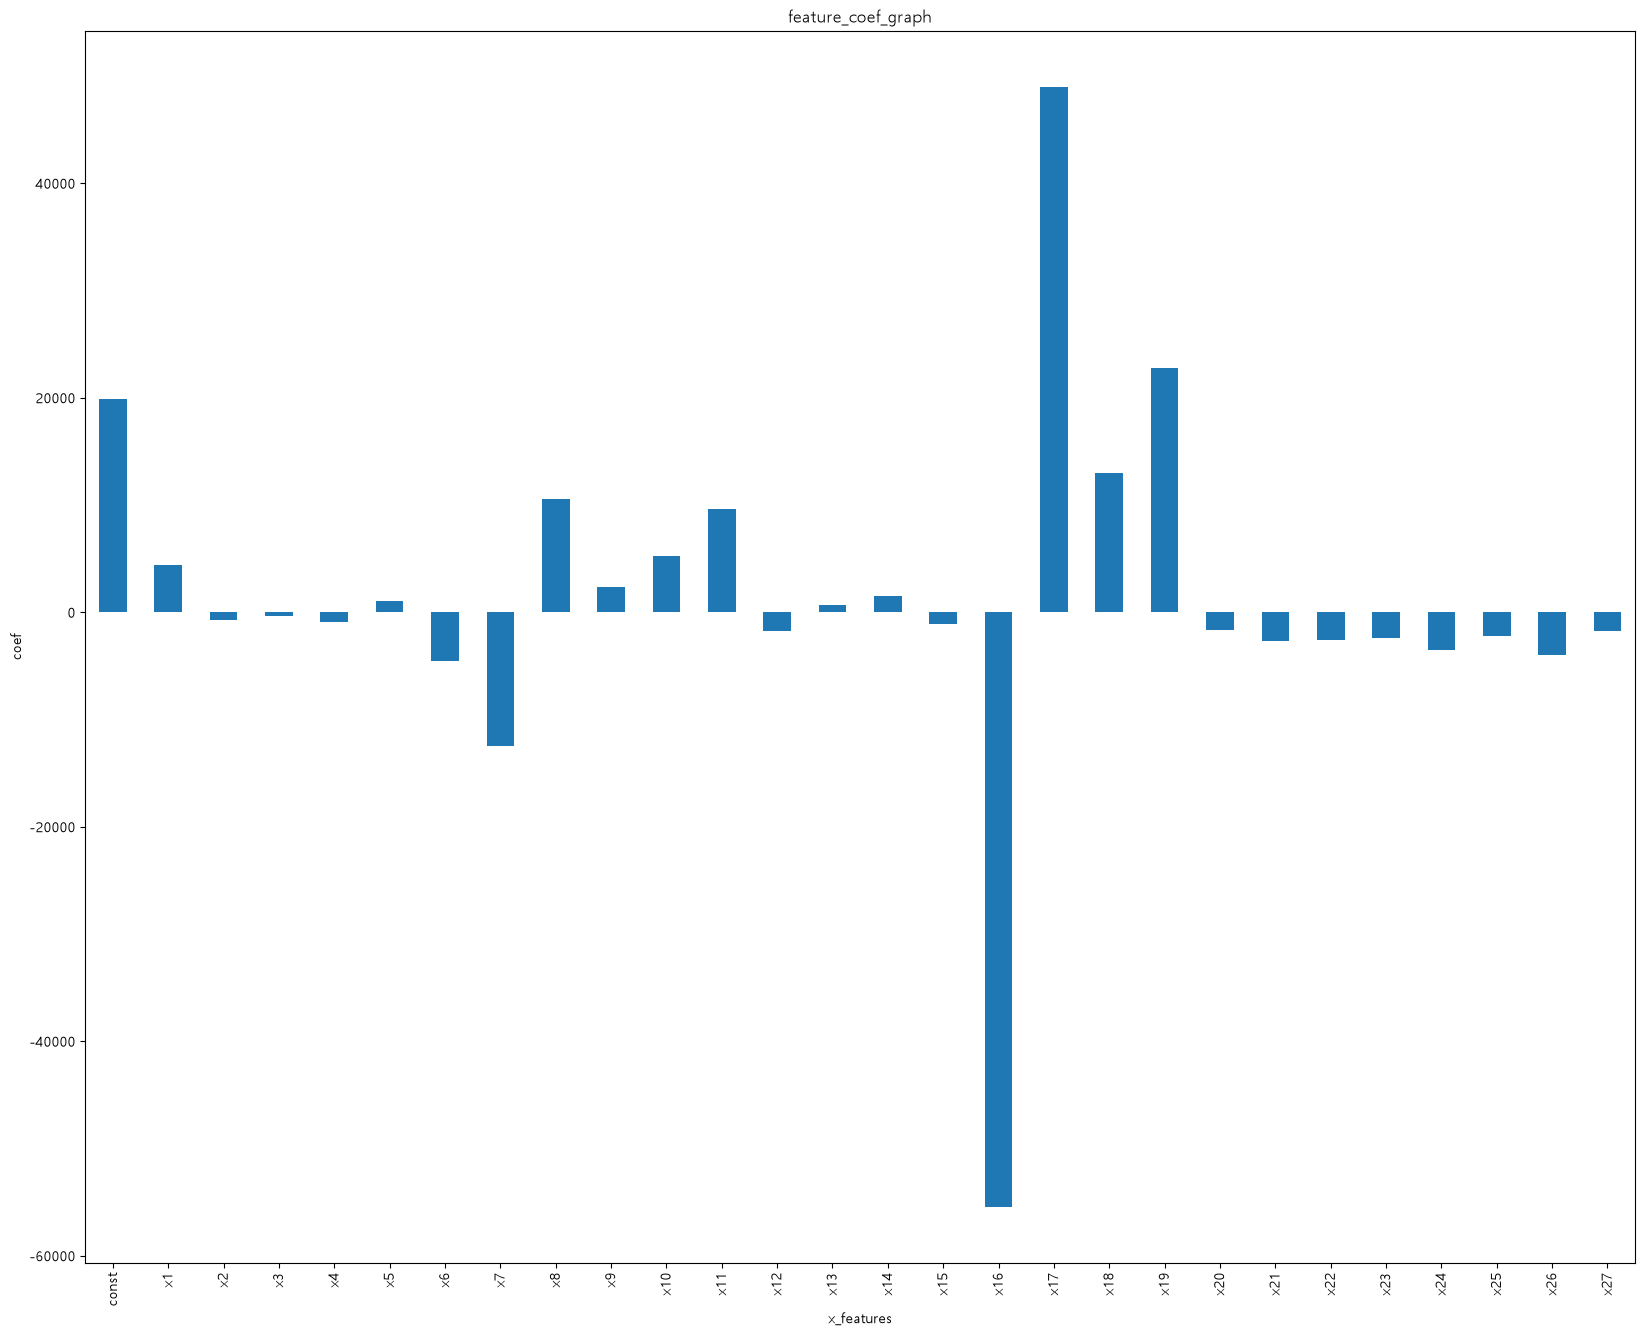

In [109]:
# 결정하는 결과에 영향을 미치는 것을 파악

plt.rcParams['figure.figsize'] = [20, 16]

# 회귀 계수를 리스트로 반환합니다.
coefs = model.params.tolist()
coefs_series = pd.Series(coefs)

# 변수명을 리스트로 반환합니다.
x_labels = model.params.index.tolist()

# 회귀 계수를 출력합니다.
ax = coefs_series.plot(kind='bar')
ax.set_title('feature_coef_graph')
ax.set_xlabel('x_features')
ax.set_ylabel('coef')
ax.set_xticklabels(x_labels)